In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

In [3]:
TICKETS_PATH = "../data/raw/support_tickets.csv"

tickets_df = pd.read_csv(TICKETS_PATH)

print("Dataset shape:", tickets_df.shape)
display(tickets_df.head())

Dataset shape: (10000, 15)


,ticket_id,created_date,ticket_text,product_name,product_segment,ticket_category,priority,sentiment,confidence_score,escalated,resolution_text,resolved_date,resolution_days,auto_resolved,customer_satisfaction_score
0,TKT100000,2023-08-12,The lipstick I received in order #ORD5614226 s...,lipstick,Beauty & Personal Care,Product Issue,High,Negative,0.66,Yes,Full refund processed. Seller account flagged ...,2023-08-14,2,No,1
1,TKT100001,2023-12-11,The shoe rack received in order #ORD8038374 ha...,shoe rack,Home & Kitchen,Product Issue,High,Negative,0.74,Yes,Missing accessory shipped separately at no add...,2023-12-12,1,No,1
2,TKT100002,2024-01-06,I want to exchange my conditioner (order #ORD6...,conditioner,Beauty & Personal Care,Refund & Return,Low,Positive,0.93,No,Accidental order refund approved. Amount credi...,2024-01-16,10,Yes,4
3,TKT100003,2024-11-17,My makeup brush set from order #ORD4823498 app...,makeup brush set,Beauty & Personal Care,Product Issue,High,Very Negative,0.78,Yes,Missing accessory shipped separately at no add...,2024-11-20,3,No,1
4,TKT100004,2023-08-23,Product listing for lipstick is completely mis...,lipstick,Beauty & Personal Care,Product Issue,Medium,Neutral,0.94,No,Replacement lipstick dispatched after quality ...,2023-08-24,1,No,4


In [4]:
model_df = tickets_df[["ticket_text", "ticket_category"]].copy()

print("Modeling dataset shape:", model_df.shape)

display(model_df.head())

Modeling dataset shape: (10000, 2)


,ticket_text,ticket_category
0,The lipstick I received in order #ORD5614226 s...,Product Issue
1,The shoe rack received in order #ORD8038374 ha...,Product Issue
2,I want to exchange my conditioner (order #ORD6...,Refund & Return
3,My makeup brush set from order #ORD4823498 app...,Product Issue
4,Product listing for lipstick is completely mis...,Product Issue


In [5]:
print("Missing ticket text:")
print(model_df["ticket_text"].isna().sum())

print("\nMissing categories:")
print(model_df["ticket_category"].isna().sum())

Missing ticket text:
0

Missing categories:
0


In [6]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    text = text.strip()
    return text

model_df["clean_text"] = model_df["ticket_text"].apply(clean_text)

display(model_df[["ticket_text", "clean_text"]].head())

,ticket_text,clean_text
0,The lipstick I received in order #ORD5614226 s...,the lipstick i received in order #ord5614226 s...
1,The shoe rack received in order #ORD8038374 ha...,the shoe rack received in order #ord8038374 ha...
2,I want to exchange my conditioner (order #ORD6...,i want to exchange my conditioner (order #ord6...
3,My makeup brush set from order #ORD4823498 app...,my makeup brush set from order #ord4823498 app...
4,Product listing for lipstick is completely mis...,product listing for lipstick is completely mis...


In [7]:
X = model_df["clean_text"]
y = model_df["ticket_category"]

print("Features:", X.shape)
print("Target:", y.shape)

print("\nCategories:")
print(y.value_counts())

Features: (10000,)
Target: (10000,)

Categories:
ticket_category
Refund & Return             2051
Delivery Issue              1950
Product Issue               1948
Payment Issue               1474
Account & Login             1030
Seller & Product Listing     830
App & Website Issue          717
Name: count, dtype: int64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

Training samples: 8000
Testing samples : 2000


In [9]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape :", X_test_tfidf.shape)

Training TF-IDF shape: (8000, 3486)
Testing TF-IDF shape : (2000, 3486)


In [10]:
intent_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

intent_model.fit(X_train_tfidf, y_train)

print("Intent model training completed.")

Intent model training completed.


In [11]:
y_pred = intent_model.predict(X_test_tfidf)

print("Predictions generated:", len(y_pred))

Predictions generated: 2000


In [12]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("=" * 50)
print("INTENT MODEL PERFORMANCE")
print("=" * 50)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

INTENT MODEL PERFORMANCE
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1 Score : 1.0000


In [13]:
print(classification_report(y_test, y_pred))

                          precision    recall  f1-score   support

         Account & Login       1.00      1.00      1.00       206
     App & Website Issue       1.00      1.00      1.00       143
          Delivery Issue       1.00      1.00      1.00       390
           Payment Issue       1.00      1.00      1.00       295
           Product Issue       1.00      1.00      1.00       390
         Refund & Return       1.00      1.00      1.00       410
Seller & Product Listing       1.00      1.00      1.00       166

                accuracy                           1.00      2000
               macro avg       1.00      1.00      1.00      2000
            weighted avg       1.00      1.00      1.00      2000



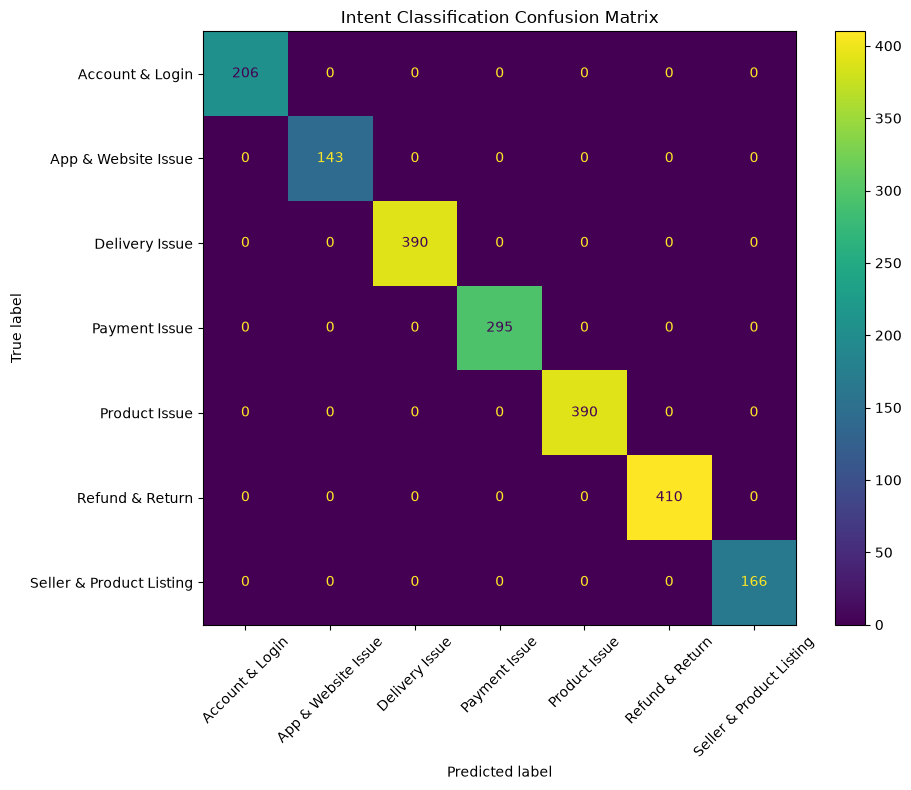

In [14]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=intent_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=intent_model.classes_
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title("Intent Classification Confusion Matrix")
plt.tight_layout()
plt.show()

## Check for possible leakage

In [ ]:
# Check category keywords
feature_names = np.array(tfidf.get_feature_names_out())

for category in intent_model.classes_:
    class_index = list(intent_model.classes_).index(category)

    coefficients = intent_model.coef_[class_index]

    top_indices = coefficients.argsort()[-10:][::-1]

    print("\n" + "=" * 60)
    print(category)
    print("=" * 60)

    print(feature_names[top_indices])


Account & Login
['account' 'my account' 'email' 'saved' 'any' 'were' 'cannot'
 'address the' 'number' 'despite']

App & Website Issue
['when' 'app' 'loading' 'page' 'doesn' 'search' 'when try' 'are not'
 'try to' 'try']

Delivery Issue
['delivery' 'delivered' 'for order' 'was' 'the delivery' 'tracking' 'to'
 'refused' 'but' 'no']

Payment Issue
['checkout' 'payment' 'failed' 'balance' 'but order' 'at checkout'
 'amount' 'charged' 'now' 'deducted']

Product Issue
['in order' 'in' 'has' 'product' 'battery' 'of' 'color' 'color of' 'from'
 'stopped']

Refund & Return
['return' 'refund' 'for' 'refund for' 'return for' 'the return'
 'return order' 'exchange' 'duplicate' 'credited to']

Seller & Product Listing
['seller' 'of' 'seller of' 'bought' 'seller is' 'the' 'ordered' 'on the'
 'is not' 'listing']


In [ ]:
# Check duplicate ticket text
duplicate_texts = model_df[
    model_df["clean_text"].duplicated(keep=False)
].sort_values("clean_text")

print("Duplicate ticket-text records:", len(duplicate_texts))

display(
    duplicate_texts[
        ["ticket_text", "ticket_category"]
    ].head(20)
)

Duplicate ticket-text records: 1447


,ticket_text,ticket_category
5626,Account is showing a different name than what ...,Account & Login
9058,Account is showing a different name than what ...,Account & Login
1510,Account is showing a different name than what ...,Account & Login
3646,Account is showing a different name than what ...,Account & Login
6221,Account is showing a different name than what ...,Account & Login
8065,Account is showing a different name than what ...,Account & Login
5047,Account is showing a different name than what ...,Account & Login
7417,Account is showing a different name than what ...,Account & Login
1285,Account is showing a different name than what ...,Account & Login
6198,Account is showing a different name than what ...,Account & Login


In [ ]:
# Check whether identical text has different categories
text_category_counts = (
    model_df
    .groupby("clean_text")["ticket_category"]
    .nunique()
)

ambiguous_texts = text_category_counts[
    text_category_counts > 1
]

print(
    "Texts appearing with multiple categories:",
    len(ambiguous_texts)
)

Texts appearing with multiple categories: 0


In [ ]:
# Check category leakage through obvious keywords
keywords = [
    "refund",
    "return",
    "delivery",
    "payment",
    "login",
    "account",
    "website",
    "app",
    "seller",
    "listing",
    "product"
]

for keyword in keywords:
    mask = model_df["clean_text"].str.contains(
        keyword,
        regex=False,
        na=False
    )

    if mask.sum() > 0:
        print(f"\nKeyword: {keyword}")
        print(
            model_df.loc[
                mask,
                "ticket_category"
            ].value_counts()
        )


Keyword: refund
ticket_category
Refund & Return    967
Delivery Issue     100
Name: count, dtype: int64

Keyword: return
ticket_category
Refund & Return        1304
Delivery Issue          122
Product Issue           108
App & Website Issue      77
Name: count, dtype: int64

Keyword: delivery
ticket_category
Delivery Issue     915
Account & Login     39
Name: count, dtype: int64

Keyword: payment
ticket_category
Payment Issue          462
Refund & Return        206
App & Website Issue     73
Delivery Issue          71
Account & Login         54
Name: count, dtype: int64

Keyword: login
ticket_category
Account & Login    100
Name: count, dtype: int64

Keyword: account
ticket_category
Account & Login    579
Refund & Return     98
Payment Issue       72
Name: count, dtype: int64

Keyword: website
ticket_category
App & Website Issue    140
Product Issue          100
Name: count, dtype: int64

Keyword: app
ticket_category
App & Website Issue    348
Payment Issue          282
Product Issue 

In [ ]:
# test the model on new, manually written tickets
new_tickets = [
    "I have been waiting for my package for several days and it still has not arrived.",
    "I was charged twice for the same order.",
    "I cannot log into my account.",
    "I want to return the product and get my money back.",
    "The product I received is damaged.",
    "The seller is using incorrect information in the product listing.",
    "The mobile app keeps crashing when I try to place an order."
]

new_clean = [clean_text(x) for x in new_tickets]

new_tfidf = tfidf.transform(new_clean)

predictions = intent_model.predict(new_tfidf)
probabilities = intent_model.predict_proba(new_tfidf).max(axis=1)

for text, prediction, confidence in zip(
    new_tickets,
    predictions,
    probabilities
):
    print("\nTicket:", text)
    print("Predicted category:", prediction)
    print("Confidence:", round(confidence, 4))


Ticket: I have been waiting for my package for several days and it still has not arrived.
Predicted category: Delivery Issue
Confidence: 0.5875

Ticket: I was charged twice for the same order.
Predicted category: Refund & Return
Confidence: 0.4036

Ticket: I cannot log into my account.
Predicted category: Account & Login
Confidence: 0.906

Ticket: I want to return the product and get my money back.
Predicted category: Refund & Return
Confidence: 0.6707

Ticket: The product I received is damaged.
Predicted category: Product Issue
Confidence: 0.705

Ticket: The seller is using incorrect information in the product listing.
Predicted category: Seller & Product Listing
Confidence: 0.4761

Ticket: The mobile app keeps crashing when I try to place an order.
Predicted category: App & Website Issue
Confidence: 0.9617


In [20]:
unique_model_df = model_df.drop_duplicates(
    subset=["clean_text"]
).copy()

print("Original records :", len(model_df))
print("Unique ticket texts:", len(unique_model_df))

print(
    "\nRemoved duplicate records:",
    len(model_df) - len(unique_model_df)
)

Original records : 10000
Unique ticket texts: 8777

Removed duplicate records: 1223


In [22]:
print(
    unique_model_df["ticket_category"].value_counts()
)

ticket_category
Refund & Return             2051
Delivery Issue              1950
Product Issue               1926
Payment Issue               1414
Seller & Product Listing     799
App & Website Issue          569
Account & Login               68
Name: count, dtype: int64


In [23]:
X_unique = unique_model_df["clean_text"]
y_unique = unique_model_df["ticket_category"]

X_train_unique, X_test_unique, y_train_unique, y_test_unique = train_test_split(
    X_unique,
    y_unique,
    test_size=0.20,
    random_state=42,
    stratify=y_unique
)

print("Training samples:", len(X_train_unique))
print("Testing samples :", len(X_test_unique))

Training samples: 7021
Testing samples : 1756


In [24]:
tfidf_unique = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_unique_tfidf = tfidf_unique.fit_transform(
    X_train_unique
)

X_test_unique_tfidf = tfidf_unique.transform(
    X_test_unique
)

print(
    "Training TF-IDF shape:",
    X_train_unique_tfidf.shape
)

print(
    "Testing TF-IDF shape:",
    X_test_unique_tfidf.shape
)

Training TF-IDF shape: (7021, 3154)
Testing TF-IDF shape: (1756, 3154)


In [25]:
intent_model_unique = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

intent_model_unique.fit(
    X_train_unique_tfidf,
    y_train_unique
)

print("Corrected intent model training completed.")

Corrected intent model training completed.


In [26]:
y_pred_unique = intent_model_unique.predict(
    X_test_unique_tfidf
)

accuracy_unique = accuracy_score(
    y_test_unique,
    y_pred_unique
)

precision_unique = precision_score(
    y_test_unique,
    y_pred_unique,
    average="weighted"
)

recall_unique = recall_score(
    y_test_unique,
    y_pred_unique,
    average="weighted"
)

f1_unique = f1_score(
    y_test_unique,
    y_pred_unique,
    average="weighted"
)

print("=" * 60)
print("CORRECTED INTENT MODEL PERFORMANCE")
print("=" * 60)

print(f"Accuracy : {accuracy_unique:.4f}")
print(f"Precision: {precision_unique:.4f}")
print(f"Recall   : {recall_unique:.4f}")
print(f"F1 Score : {f1_unique:.4f}")

CORRECTED INTENT MODEL PERFORMANCE
Accuracy : 0.9994
Precision: 0.9994
Recall   : 0.9994
F1 Score : 0.9994


In [27]:
print(
    classification_report(
        y_test_unique,
        y_pred_unique
    )
)

                          precision    recall  f1-score   support

         Account & Login       1.00      0.93      0.96        14
     App & Website Issue       1.00      1.00      1.00       114
          Delivery Issue       1.00      1.00      1.00       390
           Payment Issue       1.00      1.00      1.00       283
           Product Issue       1.00      1.00      1.00       385
         Refund & Return       1.00      1.00      1.00       410
Seller & Product Listing       1.00      1.00      1.00       160

                accuracy                           1.00      1756
               macro avg       1.00      0.99      0.99      1756
            weighted avg       1.00      1.00      1.00      1756



In [29]:
# Create model directory
import os

MODEL_DIR = "../models/intent"

os.makedirs(MODEL_DIR, exist_ok=True)

print("Model directory ready:", MODEL_DIR)

Model directory ready: ../models/intent


In [30]:
# Save model
import joblib

joblib.dump(
    intent_model_unique,
    f"{MODEL_DIR}/intent_model.pkl"
)

joblib.dump(
    tfidf_unique,
    f"{MODEL_DIR}/tfidf_vectorizer.pkl"
)

print("Intent model saved successfully.")
print("TF-IDF vectorizer saved successfully.")

Intent model saved successfully.
TF-IDF vectorizer saved successfully.


In [34]:
print(os.listdir(MODEL_DIR))

['intent_model.pkl', 'tfidf_vectorizer.pkl']


In [31]:
loaded_model = joblib.load(
    f"{MODEL_DIR}/intent_model.pkl"
)

loaded_vectorizer = joblib.load(
    f"{MODEL_DIR}/tfidf_vectorizer.pkl"
)

test_text = "My package has not arrived yet"

test_vector = loaded_vectorizer.transform(
    [clean_text(test_text)]
)

prediction = loaded_model.predict(test_vector)[0]

probabilities = loaded_model.predict_proba(test_vector)[0]
confidence = probabilities.max()

print("Ticket:", test_text)
print("Predicted category:", prediction)
print("Confidence:", round(confidence, 4))

Ticket: My package has not arrived yet
Predicted category: Delivery Issue
Confidence: 0.3485


In [32]:
probabilities = loaded_model.predict_proba(test_vector)[0]

In [33]:
confidence = probabilities.max()